# Global Power Plant Database Analysis
**Author:** Husnain Zahoor  
**Date:** Nov 25, 2026  
**Dataset:** Global Power Plant Database v1.2.0 (released 2019-06-12), World Resources Institute and data contributors.

**Version check:** I also checked the newer WRI v1.3.0 (June 2021). Saudi Arabia has 90 plants there but no reported generation for 2013 to 2019, so it would not remove the Saudi generation gap.

**Decision:** I kept v1.2.0 because it meets all Must-Have requirements and switching would not fix the limitation. The newer version is noted as a limitation in the write-up.

**Source URL:** https://datasets.wri.org/dataset/globalpowerplantdatabase

**Downloaded from:** Kaggle copy of the WRI release, https://www.kaggle.com/datasets/mathurinache/global-power-plant-database
**Licence:** CC BY 4.0. Copyright 2018-2019 World Resources Institute and Data Contributors

**Credit:** Global Energy Observatory, Google, KTH Royal Institute of Technology in Stockholm, Enipedia, World Resources Institute. 2019. Global Power Plant Database.

**Substitute dataset (For time series only):** U.S. Energy Information Administration (EIA), Electric Power Monthly, Appendix C, "Net Generation by State by Type of Producer by Energy Source" (file generation_monthly.xlsx). https://www.eia.gov/electricity/monthly/

---

### Context & Pipeline Position
This is notebook 5 of 5 (Advanced Temporal Analysis). It has two parts:

1. **Lesson 6 exercises (1 to 5):** decomposition, stationarity test, differencing and autocorrelation on a **substitute dataset**: US monthly natural gas generation from EIA. My plant data has only 5 yearly points per fuel, too few for these techniques.
2. **Sub-question 4 (own plant data):** How did total generation (generation_gwh_2013 to generation_gwh_2017) change year over year by primary_fuel, and what is the % change 2013 to 2017 for the top 3 fuel types by volume? This is a simple year-over-year comparison, not a Lesson 6 technique.

**Inputs:** generation_monthly.xlsx (EIA, 2001 to 2025 final tabs); cleaned_power_plants.csv (notebook 1).

**Outputs:** eia_gas_monthly_2010_2025.csv, gas_differenced.csv, decomposition_gas.png, differenced_gas.png, acf_gas.png, subq4_generation_by_fuel.png, and the findings text for Capstone_Findings.docx.

**Scope:** the Lesson 6 exercises describe US natural gas generation only and say nothing about Saudi demand patterns. The Sub-question 4 section covers plants that report generation in all five years (about 91% US) and is not a Saudi result.

# Environment Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
DATA_PATH = '/content/drive/MyDrive/Lumen Capstone Project/Dataset/'
OUTPUT_PATH = '/content/drive/MyDrive/Lumen Capstone Project/Output/'

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf
import warnings
warnings.filterwarnings("ignore")

In [4]:
# FORCE PANDAS TO SHOW ALL COLUMNS HORIZONTALLY (NO WRAPPING)
pd.set_option('display.max_columns', None)  # Show every column
pd.set_option('display.width', 1000)        # Give the text engine plenty of horizontal width

# Part 1: Lesson 6 Exercises (substitute dataset: EIA US monthly generation)

## Exercise 1
Prepare your time series data. Confirm that your dataset has a genuine, regularly spaced time variable. If it does not, source a substitute dataset for this lesson only, and in a markdown cell explain why it qualifies and how it connects to your research questions. Set your date column as the index. Decide whether to subset your data, and in a markdown cell explain your reasoning either way. Plot the result as a line chart. Submit your prepared dataframe, your reasoning, and your line chart.

In [5]:
# The EIA workbook has one tab per year (or period). Tabs from 2012 onward have a title row
# above the real header, so the code finds the row that starts with YEAR on each tab.
# This cell takes a few minutes because Excel files read slowly.

xl = pd.ExcelFile(DATA_PATH + 'generation_monthly.xlsx')
data_sheets = [s for s in xl.sheet_names if s not in ('EnergySource_Notes', '2026_Preliminary')]
print("Tabs used:", len(data_sheets), "|", data_sheets[0], "to", data_sheets[-1])

frames = []
for s in data_sheets:
    raw = xl.parse(s, header=None)
    hdr = raw.index[raw.iloc[:, 0].astype(str).str.strip().str.upper() == 'YEAR'][0]
    d = xl.parse(s, header=hdr)
    d.columns = (d.columns.astype(str).str.strip().str.lower()
                 .str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_'))
    frames.append(d)

df_all = pd.concat(frames, ignore_index=True)
df_all = df_all.rename(columns={'generation_megawatthours': 'generation_mwh'})

# The state label is "US-TOTAL" in the 2001-2011 tabs and "US-Total" from 2012. Make it consistent.
df_all['state'] = df_all['state'].str.strip().str.upper()

print(df_all.shape)
print(df_all.columns.tolist())
print(df_all['year'].min(), df_all['year'].max())
print(df_all.isnull().sum())
print(df_all[df_all['state'].str.contains('US')]['state'].unique())    # expect ['US-TOTAL']

Tabs used: 19 | 2001_2002_FINAL to 2025_Final
(588401, 6)
['year', 'month', 'state', 'type_of_producer', 'energy_source', 'generation_mwh']
2001 2025
year                0
month               0
state               0
type_of_producer    0
energy_source       0
generation_mwh      0
dtype: int64
['US-TOTAL']


***Data preparation log (EIA file)***

- **Source file:** one Excel workbook with one tab per year or period. I stacked the tabs 2001 to 2025 (final data), giving 588,401 rows and 6 columns with no missing values.
- **Tabs left out:** `2026_Preliminary` (partial and preliminary, while all other tabs are final) and `EnergySource_Notes` (notes, not data).
- **Header problem:** from the 2012 tab onward there is a title row above the real header. Read the normal way, those tabs produced wrong columns and the data stopped at 2011. The code now finds the row that starts with YEAR on each tab.
- **Inconsistent label:** the national total is written `US-TOTAL` in the 2001 to 2011 tabs and `US-Total` from 2012. My first filter matched only the upper-case version and silently returned 132 months instead of 300. I made the label upper case. After the fix the series has 300 months.
- **Avoiding double counting:** the file holds state rows and a national total row, and a total-all-producers row next to individual producer types. I use only `state = US-TOTAL` and `type_of_producer = Total Electric Power Industry`, so no electricity is counted twice.

In [6]:
# Series: US natural gas, national total, all producers
gas = df_all[(df_all['energy_source'] == 'Natural Gas') &
             (df_all['state'] == 'US-TOTAL') &
             (df_all['type_of_producer'] == 'Total Electric Power Industry')].copy()

print(len(gas), "rows (expect 300 = 25 years x 12 months)")
print("Duplicate months:", gas.duplicated(subset=['year', 'month']).sum())
print("Negative values:", (gas['generation_mwh'] < 0).sum())

gas['date'] = pd.to_datetime(dict(year=gas['year'], month=gas['month'], day=1))
ts = gas.set_index('date')['generation_mwh'].sort_index().asfreq('MS')
print("Missing months:", ts.isna().sum())
print("Detected frequency:", pd.infer_freq(ts.index))      # MS = month start, regular
print(ts.head())

300 rows (expect 300 = 25 years x 12 months)
Duplicate months: 0
Negative values: 0
Missing months: 0
Detected frequency: MS
date
2001-01-01    42388663.0
2001-02-01    37966927.0
2001-03-01    44364414.0
2001-04-01    45842746.0
2001-05-01    50934205.0
Freq: MS, Name: generation_mwh, dtype: float64


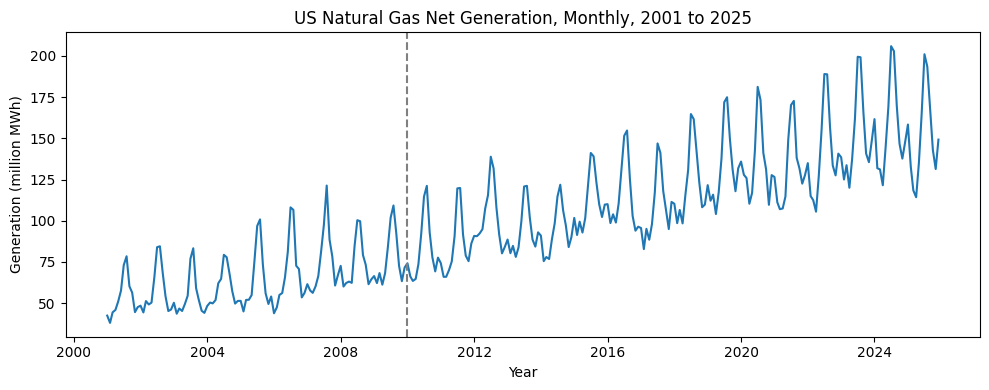

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(ts.index, ts / 1e6)
plt.axvline(pd.Timestamp('2010-01-01'), linestyle='--', color='grey')   # candidate start, move it as needed
plt.title("US Natural Gas Net Generation, Monthly, 2001 to 2025")
plt.xlabel("Year")
plt.ylabel("Generation (million MWh)")
plt.tight_layout()
plt.show()

192 2010-01-01 2025-12-01


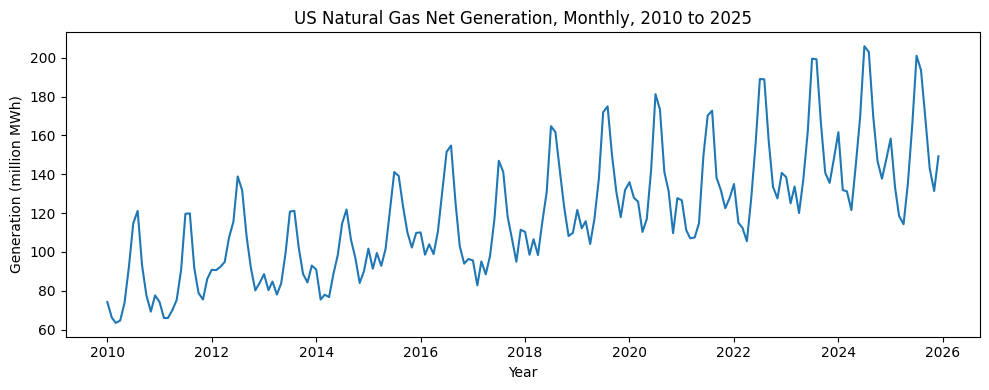

In [8]:
ts_sub = ts.loc['2010-01-01':]
print(len(ts_sub), ts_sub.index.min().date(), ts_sub.index.max().date())   # expect 192, 2010-01-01, 2025-12-01
ts_sub.to_csv(OUTPUT_PATH + 'eia_gas_monthly_2010_2025.csv', header=True)

plt.figure(figsize=(10, 4))
plt.plot(ts_sub.index, ts_sub / 1e6)
plt.title("US Natural Gas Net Generation, Monthly, 2010 to 2025")
plt.xlabel("Year")
plt.ylabel("Generation (million MWh)")
plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'gas_subset_2010_2025.png', dpi=200, bbox_inches='tight')
plt.show()

***Why a substitute dataset, and why this period?***

**Does my own data have a usable time variable?** My plant data has a regular yearly time variable (generation 2013 to 2017), but only 5 points per fuel and no seasons inside the year. Lesson 6 needs dozens of points (the lesson example has 146), so decomposition, the Dickey-Fuller test and the ACF cannot give reliable results on 5 points. The lesson allows a substitute dataset for this case.

**Why the EIA data qualifies:**
- Monthly interval, regular: 300 months from January 2001 to December 2025, with 0 missing months, 0 duplicate months and 0 negative values.
- Same research theme as my project: electricity generation by fuel.
- Same grid as my modelling data: the US makes up 95% of the plants in my modelling set (8,345 of 8,778).
- I chose natural gas because gas was the fastest-growing of the top three fuels in my Sub-question 4 result (+14.9%, 2013 to 2017).
- Official US government source, cited in the header.

**How it connects:** it applies the Lesson 6 techniques to a question about generation by fuel over time, using a dataset long enough to support them. It does not replace my plant data. My answer to Sub-question 4 comes from the plant data (Part 2).

**Why I start in 2010:** I looked at the full 2001 to 2025 chart first.
- From 2001 to 2009 the line is narrow summer spikes on a low baseline (low months about 45 to 62 million MWh), and 2008 to 2009 is flat and uneven.
- From 2010 the whole line climbs steadily: the lowest month of each year rises from about 63 million MWh in 2010 to about 114 in 2025.
- 192 months remain, more than the lesson's 146 and 16 full yearly cycles.

There is no sharp break like the one in the lesson's example, so this is a judgment call, not a test. I did not investigate why the pattern changed around 2010.

**Data used:** 2001 to 2025 final data. 2026 preliminary data is excluded.

**Limit:** this is a US series. It shows the method on the grid behind my modelling plants and says nothing about Saudi demand patterns.

## Exercise 2
Decompose your series. Run seasonal_decompose() on your data. In a markdown cell, state whether you used an additive or multiplicative model and why. Plot the decomposition. In a markdown cell, interpret what the trend, seasonal, and residual panels show about your data. Submit your decomposition figure and your interpretation.

In [9]:
# Work in million MWh so numbers are readable
y = ts_sub / 1e6
y.name = "Natural Gas Generation (million MWh)"

# Check 1: does the seasonal swing grow when the level grows?
yr = y.groupby(y.index.year).agg(['mean', 'max', 'min'])
yr['swing'] = yr['max'] - yr['min']
yr['swing_pct_of_mean'] = yr['swing'] / yr['mean'] * 100
print(yr.round(1))
print("\nCorrelation between yearly mean and yearly swing:", round(yr['mean'].corr(yr['swing']), 2))

# Check 2: fit both models and compare residual size relative to the level
add = sm.tsa.seasonal_decompose(y, model="additive", period=12)
mul = sm.tsa.seasonal_decompose(y, model="multiplicative", period=12)
print("\nAdditive residual, as a share of trend (std):", round((add.resid / add.trend).std(), 4))
print("Multiplicative residual (std):               ", round(mul.resid.std(), 4))

       mean    max    min  swing  swing_pct_of_mean
date                                               
2010   82.3  121.2   63.4   57.7               70.1
2011   84.5  119.9   65.9   53.9               63.8
2012  102.2  138.9   80.2   58.7               57.5
2013   93.7  121.2   78.0   43.1               46.0
2014   93.5  121.8   75.4   46.4               49.6
2015  111.1  141.1   91.3   49.8               44.8
2016  114.9  154.8   93.9   60.8               53.0
2017  108.0  146.9   82.8   64.2               59.4
2018  122.4  164.7   98.4   66.4               54.2
2019  132.1  175.0  104.1   70.9               53.7
2020  135.3  181.2  109.7   71.6               52.9
2021  131.6  172.7  107.0   65.7               49.9
2022  140.6  189.0  105.5   83.5               59.4
2023  150.5  199.5  120.0   79.5               52.8
2024  155.8  206.0  121.5   84.4               54.2
2025  150.9  201.1  114.3   86.8               57.5

Correlation between yearly mean and yearly swing: 0.89

Additiv

**Model used: multiplicative, period = 12**

**Why period = 12:** the data is monthly and the seasonal pattern repeats every 12 months. The lesson used period = 4 because its data was quarterly.

**Why multiplicative:** the lesson's rule is that a multiplicative model fits when the seasonal swing grows with the level of the series. Two checks on my data:
1. The yearly peak-to-trough swing and the yearly average move together (correlation 0.89). The average rose from 82.3 to 150.9 million MWh (about +83%) from 2010 to 2025, and the swing rose from 57.7 to 86.8 (about +50%).
2. The multiplicative model leaves smaller residuals: 0.0421, against 0.0496 for the additive model (measured as a share of the trend).

Both checks support the multiplicative model. One caution: the swing grew less than the level (+50% vs +83%), so it is not growing fully in proportion. Multiplicative is still the better of the two.

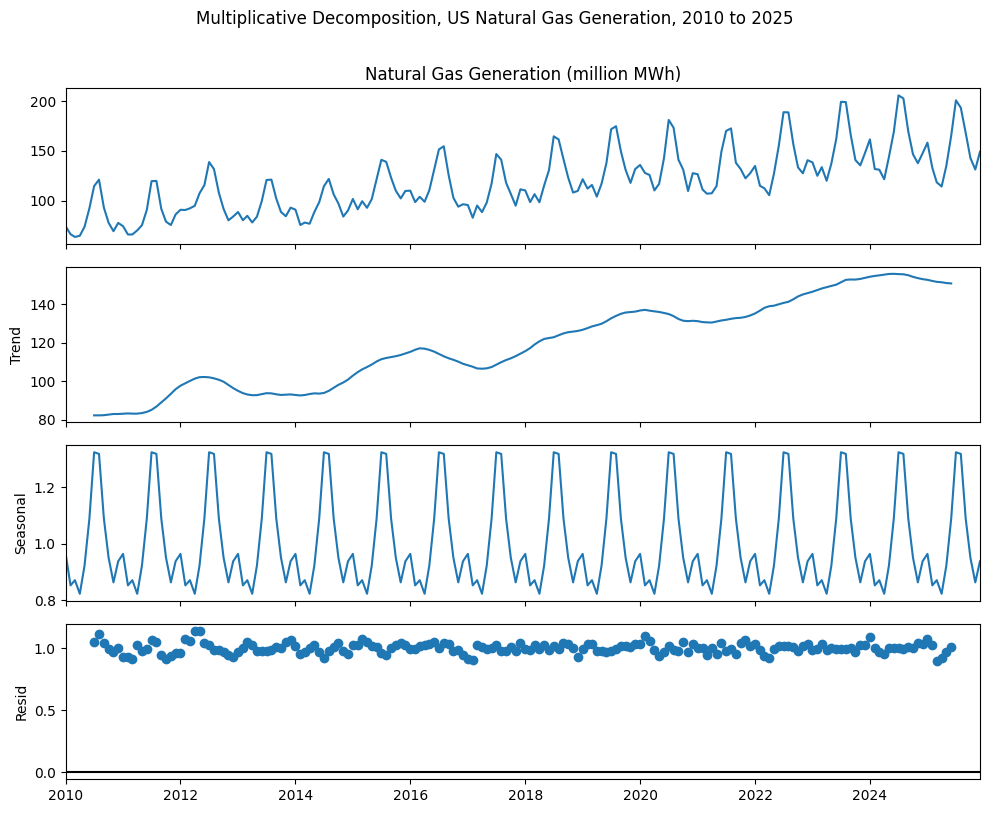

In [10]:
fig = mul.plot()
fig.set_size_inches(10, 8)
fig.suptitle("Multiplicative Decomposition, US Natural Gas Generation, 2010 to 2025", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'decomposition_gas.png', dpi=200, bbox_inches='tight')
plt.show()

In [11]:
# numbers for the interpretation
dec = mul

seasonal_by_month = dec.seasonal.groupby(dec.seasonal.index.month).mean()
print("Seasonal factor by month:\n", seasonal_by_month.round(3))
print("\nPeak month:  ", seasonal_by_month.idxmax(), "factor", round(seasonal_by_month.max(), 3))
print("Lowest month:", seasonal_by_month.idxmin(), "factor", round(seasonal_by_month.min(), 3))

trend = dec.trend.dropna()
print("\nTrend start:", trend.index[0].date(), round(trend.iloc[0], 1))
print("Trend end:  ", trend.index[-1].date(), round(trend.iloc[-1], 1))
print("Trend low:  ", trend.idxmin().date(), round(trend.min(), 1))
print("Trend high: ", trend.idxmax().date(), round(trend.max(), 1))

resid = dec.resid.dropna()
print("\nResidual std:", round(resid.std(), 4))
print("Five largest departures from 1.0:")
print((resid - 1).abs().nlargest(5).round(3))

Seasonal factor by month:
 date
1     0.964
2     0.852
3     0.870
4     0.822
5     0.922
6     1.089
7     1.324
8     1.318
9     1.089
10    0.950
11    0.863
12    0.937
Name: seasonal, dtype: float64

Peak month:   7 factor 1.324
Lowest month: 4 factor 0.822

Trend start: 2010-07-01 82.3
Trend end:   2025-06-01 150.8
Trend low:   2010-08-01 82.3
Trend high:  2024-06-01 155.8

Residual std: 0.0421
Five largest departures from 1.0:
date
2012-05-01    0.140
2012-04-01    0.138
2010-08-01    0.117
2025-03-01    0.103
2017-02-01    0.097
Name: resid, dtype: float64


**What the three panels show**

- **Trend:** rises from about 82.3 million MWh (mid-2010) to about 150.8 (mid-2025), roughly +83%. It reached its highest point, 155.8, in June 2024 and then edged down about 3%. On the way up there are short flat or falling stretches around 2012 to 2014, 2016 to 2017 and 2020 to 2021 (read from the chart, not from a test). The trend is the main movement in this series.
- **Seasonal:** repeats every 12 months. July is the peak month at a factor of 1.324 (August is almost equal at 1.318), so a typical July runs about 32% above the trend. April is the lowest at 0.822, about 18% below. There is a smaller bump in December and January (0.937 and 0.964) over the spring months. A likely reason is that electricity demand rises in the hot months and gas plants cover much of it. I have not tested this.
- **Residual:** stays close to 1.0 with a standard deviation of 0.042, so what is left after trend and seasons is typically about 4%. The widest departures are April and May 2012 (about 14%), August 2010 (about 12%), March 2025 (about 10%) and February 2017 (about 10%). I did not investigate what happened in those months.

**Note:** the trend line starts and ends 6 months in from the edges, because the moving average needs 6 months on each side. The flat line at 0 in the residual panel is a plotting default, not data.

**Limit:** this is US data. It shows the method on the grid behind my modelling plants and says nothing about Saudi demand patterns.

## Exercise 3
Test for stationarity. State your null and alternative hypotheses. Run the Dickey-Fuller test. In a markdown cell, interpret the result: compare the test statistic to the critical values, and state whether your data is stationary. Submit your test output and your interpretation.

***Hypotheses:***

**Why test:** forecasting methods assume the series' mean and variance stay stable. My series has a visible upward trend and a seasonal pattern, so it probably isn't stationary. The chart is only a first impression, so I test it formally.

- **H0 (null):** the series has a unit root, meaning it is non-stationary.
- **H1 (alternative):** the series does not have a unit root, meaning it is stationary.

**Decision rule:** if the test statistic is more negative than the critical value (and the p-value is below 0.05), reject H0. Otherwise I cannot reject it.

In [12]:
# helper and test
def adf_report(series, label):
    res = adfuller(series.dropna())
    out = pd.Series(res[0:4], index=["Test Statistic", "p-value", "Number of Lags Used", "Number of Observations Used"])
    for k, v in res[4].items():
        out[f"Critical Value ({k})"] = v
    print(label)
    print(out.round(4))
    reject_5 = (res[0] < res[4]['5%']) and (res[1] < 0.05)
    print("-> At the 5% level:", "REJECT H0, stationary" if reject_5 else "CANNOT REJECT H0, not stationary")
    print()
    return out

adf_level = adf_report(y, "Dickey-Fuller test, level data (2010 to 2025)")

Dickey-Fuller test, level data (2010 to 2025)
Test Statistic                  -1.3687
p-value                          0.5972
Number of Lags Used             13.0000
Number of Observations Used    178.0000
Critical Value (1%)             -3.4676
Critical Value (5%)             -2.8779
Critical Value (10%)            -2.5755
dtype: float64
-> At the 5% level: CANNOT REJECT H0, not stationary



**Result (level data, 2010 to 2025)**

- Test statistic: -1.3687
- Critical values: 1% = -3.4676, 5% = -2.8779, 10% = -2.5755
- p-value: 0.5972

The test statistic is larger than the critical value at 1%, 5% and 10%, and the p-value is far above 0.05. The null hypothesis cannot be rejected.

**Conclusion:** the level series is not stationary. This matches the upward trend in my line chart, where the mean keeps moving.

**Limit of this test:** the plain Dickey-Fuller test mainly targets trend. My series also has a strong 12-month seasonal pattern, which this test does not treat separately.

## Exercise 4
Stationarize through differencing. Apply differencing to your series. Re-run the Dickey-Fuller test. If your data is still not stationary, apply a second round of differencing and test again. Submit your differenced series, your test results, and a markdown cell explaining how many rounds you needed and how you know.

**Why:** differencing replaces each value with the change from the previous month. This removes a trend, because a trend is a level that keeps drifting in one direction.

**Plan:** apply one round, rerun the Dickey-Fuller test, and apply a second round only if the series is still non-stationary. I stop as soon as the test rejects the null, because extra differencing can add noise.

In [13]:
# differencing loop
current = y.copy()
rounds = {}

for n in range(1, 4):                                 # at most 3 rounds
    current = current.diff().dropna()
    res = adf_report(current, f"After {n} round(s) of differencing")
    rounds[n] = current
    if res["p-value"] < 0.05 and res["Test Statistic"] < res["Critical Value (5%)"]:
        break

n_rounds = n
y_diff = rounds[n_rounds]
print("Rounds needed:", n_rounds, "| observations left:", len(y_diff))

After 1 round(s) of differencing
Test Statistic                  -3.4420
p-value                          0.0096
Number of Lags Used             12.0000
Number of Observations Used    178.0000
Critical Value (1%)             -3.4676
Critical Value (5%)             -2.8779
Critical Value (10%)            -2.5755
dtype: float64
-> At the 5% level: REJECT H0, stationary

Rounds needed: 1 | observations left: 191


After one round of differencing, the test statistic (-3.44) is below the 5% critical value (-2.88) and the 10% value (-2.58), and the p-value is 0.0096. I reject the null at the 5% level, so the differenced series is stationary at that level. It is not below the 1% critical value (-3.47), so the evidence is good but not at the strictest threshold. Rounds needed: 1.

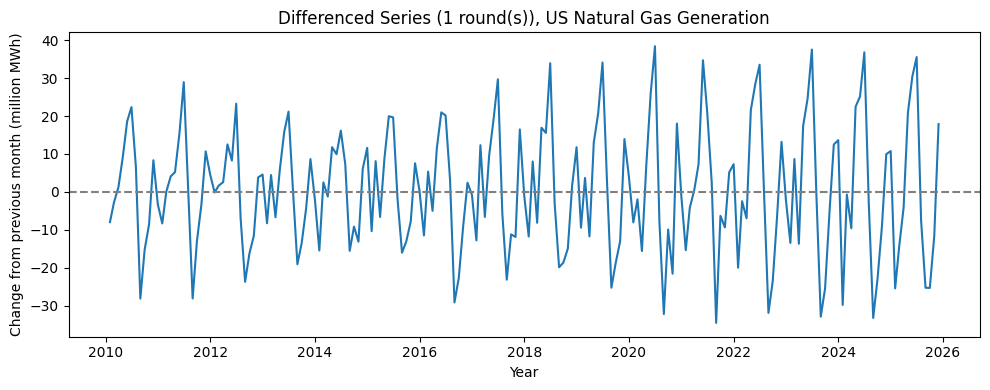

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(y_diff.index, y_diff)
plt.axhline(0, linestyle="--", color="grey")
plt.title(f"Differenced Series ({n_rounds} round(s)), US Natural Gas Generation")
plt.xlabel("Year")
plt.ylabel("Change from previous month (million MWh)")
plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'differenced_gas.png', dpi=200, bbox_inches='tight')
plt.show()

y_diff.to_csv(OUTPUT_PATH + 'gas_differenced.csv', header=True)

**Result**

| Step | Test statistic | p-value | 5% critical value | Stationary at 5%? |
|---|---|---|---|---|
| Level data | -1.3687 | 0.5972 | -2.8779 | No |
| After round 1 | -3.4420 | 0.0096 | -2.8779 | Yes |

**Rounds needed: 1.** After one round, the test statistic (-3.44) is below the 5% and 10% critical values and the p-value is 0.0096, so I reject the null at the 5% level. It is not below the 1% critical value (-3.47), so the evidence is good but not at the strictest threshold. I stopped there because a second round was not needed, and extra differencing can add noise.

**What the chart shows:** the differenced series moves around zero with no upward drift, so the trend is gone. The month-to-month swings are large and repeat every year, and they get wider over time: roughly plus or minus 20 to 30 million MWh in the early 2010s and 30 to 38 in recent years.

**Note:** the test passes at 5%, but the chart shows the seasonal ups and downs are still there and getting wider. The ACF in Exercise 5 checks how much structure is left.

## Exercise 5
Check autocorrelation and update your findings. Plot the ACF for your final, stationary series. In a markdown cell, state how many lags remain significant and what that tells you. Connect this back to your research questions. Record your findings in Capstone_Findings.docx. Submit your ACF plot, your interpretation, and the updated findings document.

**Why:** the ACF plot shows how strongly each month's value relates to the value 1, 2, 3 ... months earlier. A bar outside the shaded band is a statistically significant lag. If many lags are still significant after differencing, structure remains in the series and it may not be ready for forecasting.

**Lags shown:** 36 (three years). The lesson used 20 on quarterly data. My data is monthly, so I need at least 24 lags to see a yearly pattern at lag 12 and lag 24.

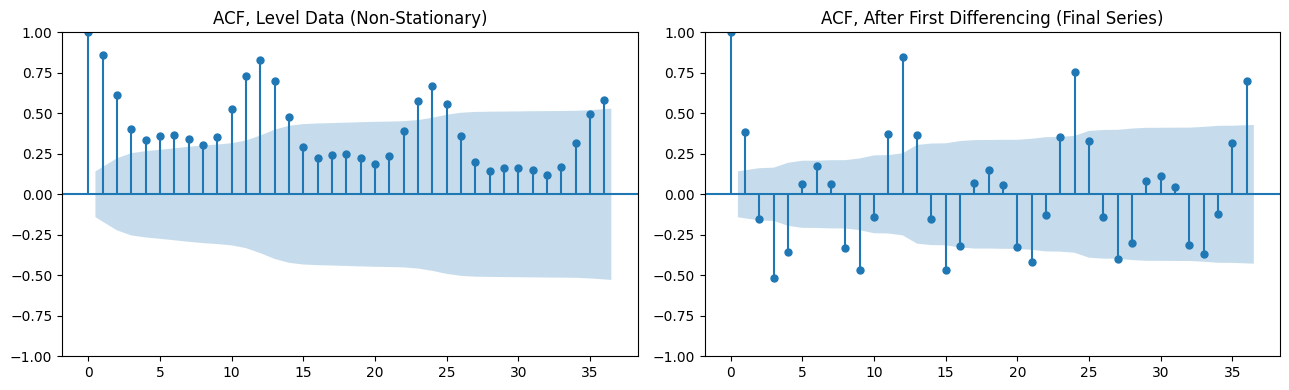

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(y, lags=36, ax=axes[0])
axes[0].set_title("ACF, Level Data (Non-Stationary)")
plot_acf(y_diff, lags=36, ax=axes[1])
axes[1].set_title("ACF, After First Differencing (Final Series)")
plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'acf_gas.png', dpi=200, bbox_inches='tight')
plt.show()

In [16]:
# count the significant lags

def significant_lags(series, nlags):
    vals, confint = acf(series, nlags=nlags, alpha=0.05)
    half_width = confint[:, 1] - vals                     # same band the plot draws
    return [i for i in range(1, nlags + 1) if abs(vals[i]) > half_width[i]], vals

sig36, vals36 = significant_lags(y_diff, 36)
sig20 = [l for l in sig36 if l <= 20]

print("Final series (differenced once)")
print("Significant lags out of first 20:", len(sig20), sig20)
print("Significant lags out of 36:      ", len(sig36), sig36)
print("Seasonal lags 12, 24, 36 significant?", {l: (l in sig36) for l in (12, 24, 36)})
print("ACF at lag 12 / 24 / 36:", round(vals36[12], 2), round(vals36[24], 2), round(vals36[36], 2))

sig_level, _ = significant_lags(y, 36)
print("\nFor comparison, level data: significant lags out of 36:", len(sig_level))

Final series (differenced once)
Significant lags out of first 20: 9 [1, 3, 4, 8, 9, 11, 12, 13, 15]
Significant lags out of 36:       14 [1, 3, 4, 8, 9, 11, 12, 13, 15, 21, 23, 24, 27, 36]
Seasonal lags 12, 24, 36 significant? {12: True, 24: True, 36: True}
ACF at lag 12 / 24 / 36: 0.85 0.76 0.7

For comparison, level data: significant lags out of 36: 18


**Result**

- **Level data:** 18 of 36 lags are significant. This matches a strong trend, where each month is tied to many months before it.
- **After one round of differencing:** 9 of the first 20 lags are significant (lags 1, 3, 4, 8, 9, 11, 12, 13, 15) and 14 of 36 overall. The lesson's rule of thumb is that about 10 or more significant lags in 20 suggests another round of differencing. My count of 9 is just below that threshold.
- **Seasonal lags:** lags 12, 24 and 36 are all significant, with ACF values of 0.85, 0.76 and 0.70.

**What this tells me:** by the lesson's count, no second round is needed. But the count understates the problem. The remaining structure is not scattered noise. It is one strong repeating 12-month pattern, with ACF values of 0.85, 0.76 and 0.70 at lags 12, 24 and 36. Differencing once removed the trend, but not the yearly seasonal pattern I saw in Exercise 2. A second ordinary difference would not fix this, because it targets trend and not seasons. The matching tool is seasonal differencing (each month minus the same month a year earlier), which this lesson does not cover and I did not run. So the series passes the stationarity test at the 5% level, but it still carries seasonal structure that a forecasting step would have to handle.

**Connection to my research question:** Sub-question 4 asks how generation changed over time by fuel. For US natural gas generation from 2010 to 2025, this analysis shows a strong upward trend (about 82 to 151 million MWh, roughly +83%), a clear yearly pattern peaking in July and August, and a seasonal structure that remains after one round of differencing. It does not answer Sub-question 4 itself. That answer comes from my plant data (Part 2), because my plant data has only 5 yearly points per fuel. This part is a method demonstration on the US grid and says nothing about Saudi demand patterns.

**Limits:** one fuel, one country, a substitute dataset. This is analysis, not a forecast.

# Part 2: Sub-question 4 (own plant data)

This part uses my own plant data, not the EIA data. It is a year-over-year comparison by fuel, not a Lesson 6 technique, because 5 yearly points are too few for decomposition or stationarity tests.

### Build the plant set

In [17]:
# cleaned_power_plants.csv
df_power = pd.read_csv(OUTPUT_PATH + 'cleaned_power_plants.csv', encoding='utf-8-sig')

years = [2013, 2014, 2015, 2016, 2017]
gen_cols = [f'generation_gwh_{y}' for y in years]

panel = df_power[df_power[gen_cols].notna().all(axis=1)].copy()
print("Plants with all 5 years:", len(panel))            # expect 6,817

panel = panel[~panel['flag_over_max'] & ~panel['flag_negative_gen_2017']]
print("After removing flagged plants:", len(panel))
print(panel['country'].value_counts())

Plants with all 5 years: 6817
After removing flagged plants: 6654
country
USA    6085
IND     372
AUS     197
Name: count, dtype: int64


### Totals, top 3 and % change

In [18]:
by_fuel = panel.groupby('primary_fuel')[gen_cols].sum()
by_fuel.columns = years
by_fuel['plants'] = panel.groupby('primary_fuel').size()
by_fuel['total_5yr_gwh'] = by_fuel[years].sum(axis=1)
by_fuel = by_fuel.sort_values('total_5yr_gwh', ascending=False)

top3 = by_fuel.head(3).index.tolist()
print("Top 3 fuels by volume:", top3)

summary = by_fuel.loc[top3, years + ['plants']].copy()
yoy = by_fuel.loc[top3, years].pct_change(axis=1).mul(100).round(1)
yoy.columns = [f'{y}' for y in years]
summary['pct_change_2013_2017'] = ((summary[2017] / summary[2013] - 1) * 100).round(1)

print("\nTotal generation (GWh) and % change:\n", summary.round({y: 0 for y in years}))
print("\nYear-over-year % change:\n", yoy.drop(columns='2013'))
print("\nAll fuels, for reference:\n", by_fuel[[2013, 2017, 'plants']].round(0))

Top 3 fuels by volume: ['Coal', 'Gas', 'Nuclear']

Total generation (GWh) and % change:
                    2013       2014       2015       2016       2017  plants  pct_change_2013_2017
primary_fuel                                                                                     
Coal          2033145.0  2099686.0  2038428.0  1891735.0  2112240.0     494                   3.9
Gas           1106560.0  1057685.0  1223184.0  1204911.0  1271578.0    1652                  14.9
Nuclear        814748.0   819593.0   827543.0   826490.0   831524.0      66                   2.1

Year-over-year % change:
               2014  2015  2016  2017
primary_fuel                        
Coal           3.3  -2.9  -7.2  11.7
Gas           -4.4  15.6  -1.5   5.5
Nuclear        0.6   1.0  -0.1   0.6

All fuels, for reference:
                    2013       2017  plants
primary_fuel                              
Coal          2033145.0  2112240.0     494
Gas           1106560.0  1271578.0    1652
Nuclear  

### US-only check and chart

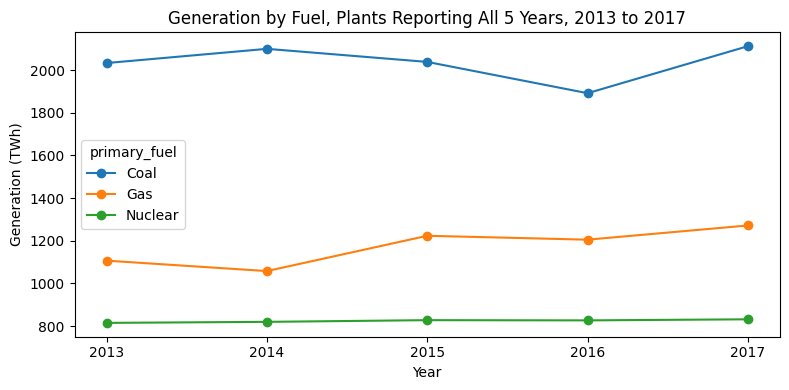

In [19]:
plot_df = (by_fuel.loc[top3, years] / 1000).T          # TWh
plot_df.index = plot_df.index.astype(int)

plot_df.plot(marker='o', figsize=(8, 4))
plt.title("Generation by Fuel, Plants Reporting All 5 Years, 2013 to 2017")
plt.xlabel("Year"); plt.ylabel("Generation (TWh)")
plt.xticks(years)
plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'subq4_generation_by_fuel.png', dpi=200)
plt.show()

In [20]:
by_cf = panel.groupby(['primary_fuel', 'country'])[gen_cols].sum()
by_cf.columns = years
by_cf = by_cf.loc[top3]
by_cf['pct_change_2013_2017'] = ((by_cf[2017] / by_cf[2013] - 1) * 100).round(1)
by_cf['plants'] = panel.groupby(['primary_fuel', 'country']).size()
print(by_cf)

                              2013          2014          2015          2016          2017  pct_change_2013_2017  plants
primary_fuel country                                                                                                    
Coal         AUS      1.339644e+05  1.266997e+05  1.386856e+05  1.412708e+05  1.406832e+05                   5.0      16
             IND      6.732812e+05  7.570333e+05  7.765273e+05  7.714225e+05  7.887270e+05                  17.1     147
             USA      1.225899e+06  1.215953e+06  1.123215e+06  9.790420e+05  1.182830e+06                  -3.5     331
Gas          AUS      3.168707e+04  3.144764e+04  2.834582e+04  2.603944e+04  2.481102e+04                 -21.7      68
             IND      4.322780e+04  4.008766e+04  4.468195e+04  4.597532e+04  4.684359e+04                   8.4      50
             USA      1.031645e+06  9.861494e+05  1.150156e+06  1.132897e+06  1.199924e+06                  16.3    1534
Nuclear      IND      3.040859e+

***Sub-question 4: Generation change by fuel, 2013 to 2017***

**Method:** only plants that report generation in all five years are used, so a rising total cannot come from plants that started reporting later. 6,817 plants report all five years. I excluded 163 plants flagged in cleaning (output above the physical maximum or negative 2017 output), as in the modelling set. 6,654 plants remain: USA 6,085, India 372, Australia 197. The US share is 91.4%.

**Top 3 fuels by five-year volume:** coal, gas, nuclear.

| Fuel | Plants | 2013 (GWh) | 2017 (GWh) | % change, all plants | % change, US only |
|---|---|---|---|---|---|
| Coal | 494 | 2,033,145 | 2,112,240 | +3.9% | -3.5% |
| Gas | 1,652 | 1,106,560 | 1,271,578 | +14.9% | +16.3% |
| Nuclear | 66 | 814,748 | 831,524 | +2.1% | +2.6% |

**Year-over-year change (all plants):**

| Fuel | 2014 | 2015 | 2016 | 2017 |
|---|---|---|---|---|
| Coal | +3.3% | -2.9% | -7.2% | +11.7% |
| Gas | -4.4% | +15.6% | -1.5% | +5.5% |
| Nuclear | +0.6% | +1.0% | -0.1% | +0.6% |

**By country, 2013 to 2017:**

| Fuel | USA | India | Australia |
|---|---|---|---|
| Coal | -3.5% (331 plants) | +17.1% (147) | +5.0% (16) |
| Gas | +16.3% (1,534) | +8.4% (50) | -21.7% (68) |
| Nuclear | +2.6% (60) | -12.2% (6) | no plants |

**What I see:**
- **Gas grew the most:** +14.9% overall and +16.3% in the US, which holds 94% of the gas generation here. The path was uneven: it fell in 2014 and 2016 and rose in 2015 and 2017.
- **Nuclear was stable:** +2.1%, with every yearly change between -0.1% and +1.0%.
- **Coal depends on the country:** US coal fell about 20% from 2013 to 2016 and then rose about 21% in 2017, ending 3.5% below 2013 (about -43 TWh). India's coal rose 17.1% (about +115 TWh) and Australia's 5.0% (about +7 TWh). India's increase outweighs the US decline, which is why the combined figure is +3.9%.

**So what:** gas shows the strongest growth in these plants. Coal is two stories, not one: falling in the US and rising in India. I do not treat the combined coal figure as a single trend.

**Limits:**
- These are the plants that report every year, not each fuel's national total, and about 91% are US.
- The 2013 to 2017 % change compares two years only. Coal in particular dipped in 2016, so the result depends on which end years are chosen.
- Five yearly points describe a change. They cannot show a statistical trend, which is why the Lesson 6 techniques ran on a substitute dataset.
- A change in generation may reflect plants running more or less, not new plants, because capacity is a single snapshot.
- Some by-country groups are small (India nuclear: 6 plants; Australia coal: 16 plants), so those percentages are less reliable.
- I have not investigated why gas rose in 2015 or why US coal fell until 2016. These are observations, not explanations.
- This is not a Saudi result: no Saudi plant reports generation.